In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import contextily as cx
import nivapy3 as nivapy
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import cartopy.crs as ccrs
import cartopy.feature as cfeature

from shapely.geometry import Point
from mpl_toolkits.axes_grid1 import make_axes_locatable

## Sites location and data selection

This notebook (i) produces a map showing the locations of sites, (ii) provides a quick description of the avaiable data for each water body, (iii) select and save the data of interest.

In [2]:
def plot_map(lon, lat, categories):
    
    fig = plt.figure(figsize=(25, 30))

    # Create a GeoAxes in the tile's projection
    ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())

    # Add coastlines and country borders
    ax.coastlines(linewidth=2)
    ax.add_feature(cfeature.BORDERS, edgecolor='black', linewidth=2)

    # Define a color map for the water categories
    colormap = {'R': 'blue', 'L': 'darkgreen', 'U': 'black', 'G': 'yellow', 'C': 'purple', 'S': 'orange', 'J': 'red'}
    for category, color in colormap.items():
        ax.scatter(lon[categories == category], lat[categories == category], color=color,  s=20, transform=ccrs.PlateCarree(), label=category)

    # Add gridlines with labels
    gl = ax.gridlines(draw_labels=True, alpha = 0)
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 25}  
    gl.ylabel_style = {'size': 25}  

    # Set the extent to show Norway
    ax.set_extent([4, 32, 57, 72], crs=ccrs.PlateCarree())

    ax.set_facecolor('white')

    legend_handles = [mlines.Line2D([], [], color=color, marker='o', linestyle='None', markersize=10, label=category) for category, color in colormap.items()]
    legend = ax.legend(handles=legend_handles, bbox_to_anchor=(1, 1), loc='upper left', title='Water Category', edgecolor='black', fontsize='xx-large',  title_fontsize='20')
    legend.get_frame().set_facecolor('white')
    legend.get_frame().set_edgecolor('black')
    legend.get_frame().set_linewidth(2)

    # Add borders around the axes
    for spine in ax.spines.values():
        spine.set_edgecolor('black')
        spine.set_linewidth(2)

    plt.show()


#### Read files and merge to a new df

In [4]:
# Read metadata and water chemistry files
meta_df = pd.read_csv("../data/raw_data/water_chemistry/ai_wc_metadata_2024.csv")
wc_df = pd.read_csv("../data/raw_data/water_chemistry/ai_wc_2024.csv")

# Select coordinates and water category from metadata file
selected_columns = meta_df[['WaterLocationCode', 'lon', 'lat', 'WaterCategory']]

# Merge water chemistry with selected metadata
merged_df = pd.merge(wc_df, selected_columns, on='WaterLocationCode')
merged_df.head()

,WaterLocationID,WaterLocationCode,Name,ActivityID,ActivityName,MediumID,SamplingTime,UpperDepth,LowerDepth,N-TOT_µg_l,P-TOT_µg_l,DOC_mg_l,TOC_mg_l,lon,lat,WaterCategory
0,27839,001-27839,Bjørkelangen (BJØ1),ANNE,Annet,VF,1972-05-08,0.0,0.0,928.0,24.0,NaN,NaN,11.532832,59.848034,L
1,27839,001-27839,Bjørkelangen (BJØ1),ANNE,Annet,VF,1972-05-08,1.0,1.0,868.0,38.0,NaN,NaN,11.532832,59.848034,L
2,27839,001-27839,Bjørkelangen (BJØ1),ANNE,Annet,VF,1972-05-08,3.0,3.0,828.0,30.0,NaN,NaN,11.532832,59.848034,L
3,27839,001-27839,Bjørkelangen (BJØ1),ANNE,Annet,VF,1972-05-08,5.0,5.0,828.0,33.0,NaN,NaN,11.532832,59.848034,L
4,27839,001-27839,Bjørkelangen (BJØ1),ANNE,Annet,VF,1972-05-08,7.0,7.0,848.0,33.0,NaN,NaN,11.532832,59.848034,L


In [5]:
merged_df["MediumID"].unique()

array(['VF'], dtype=object)

#### Geographic distribution 

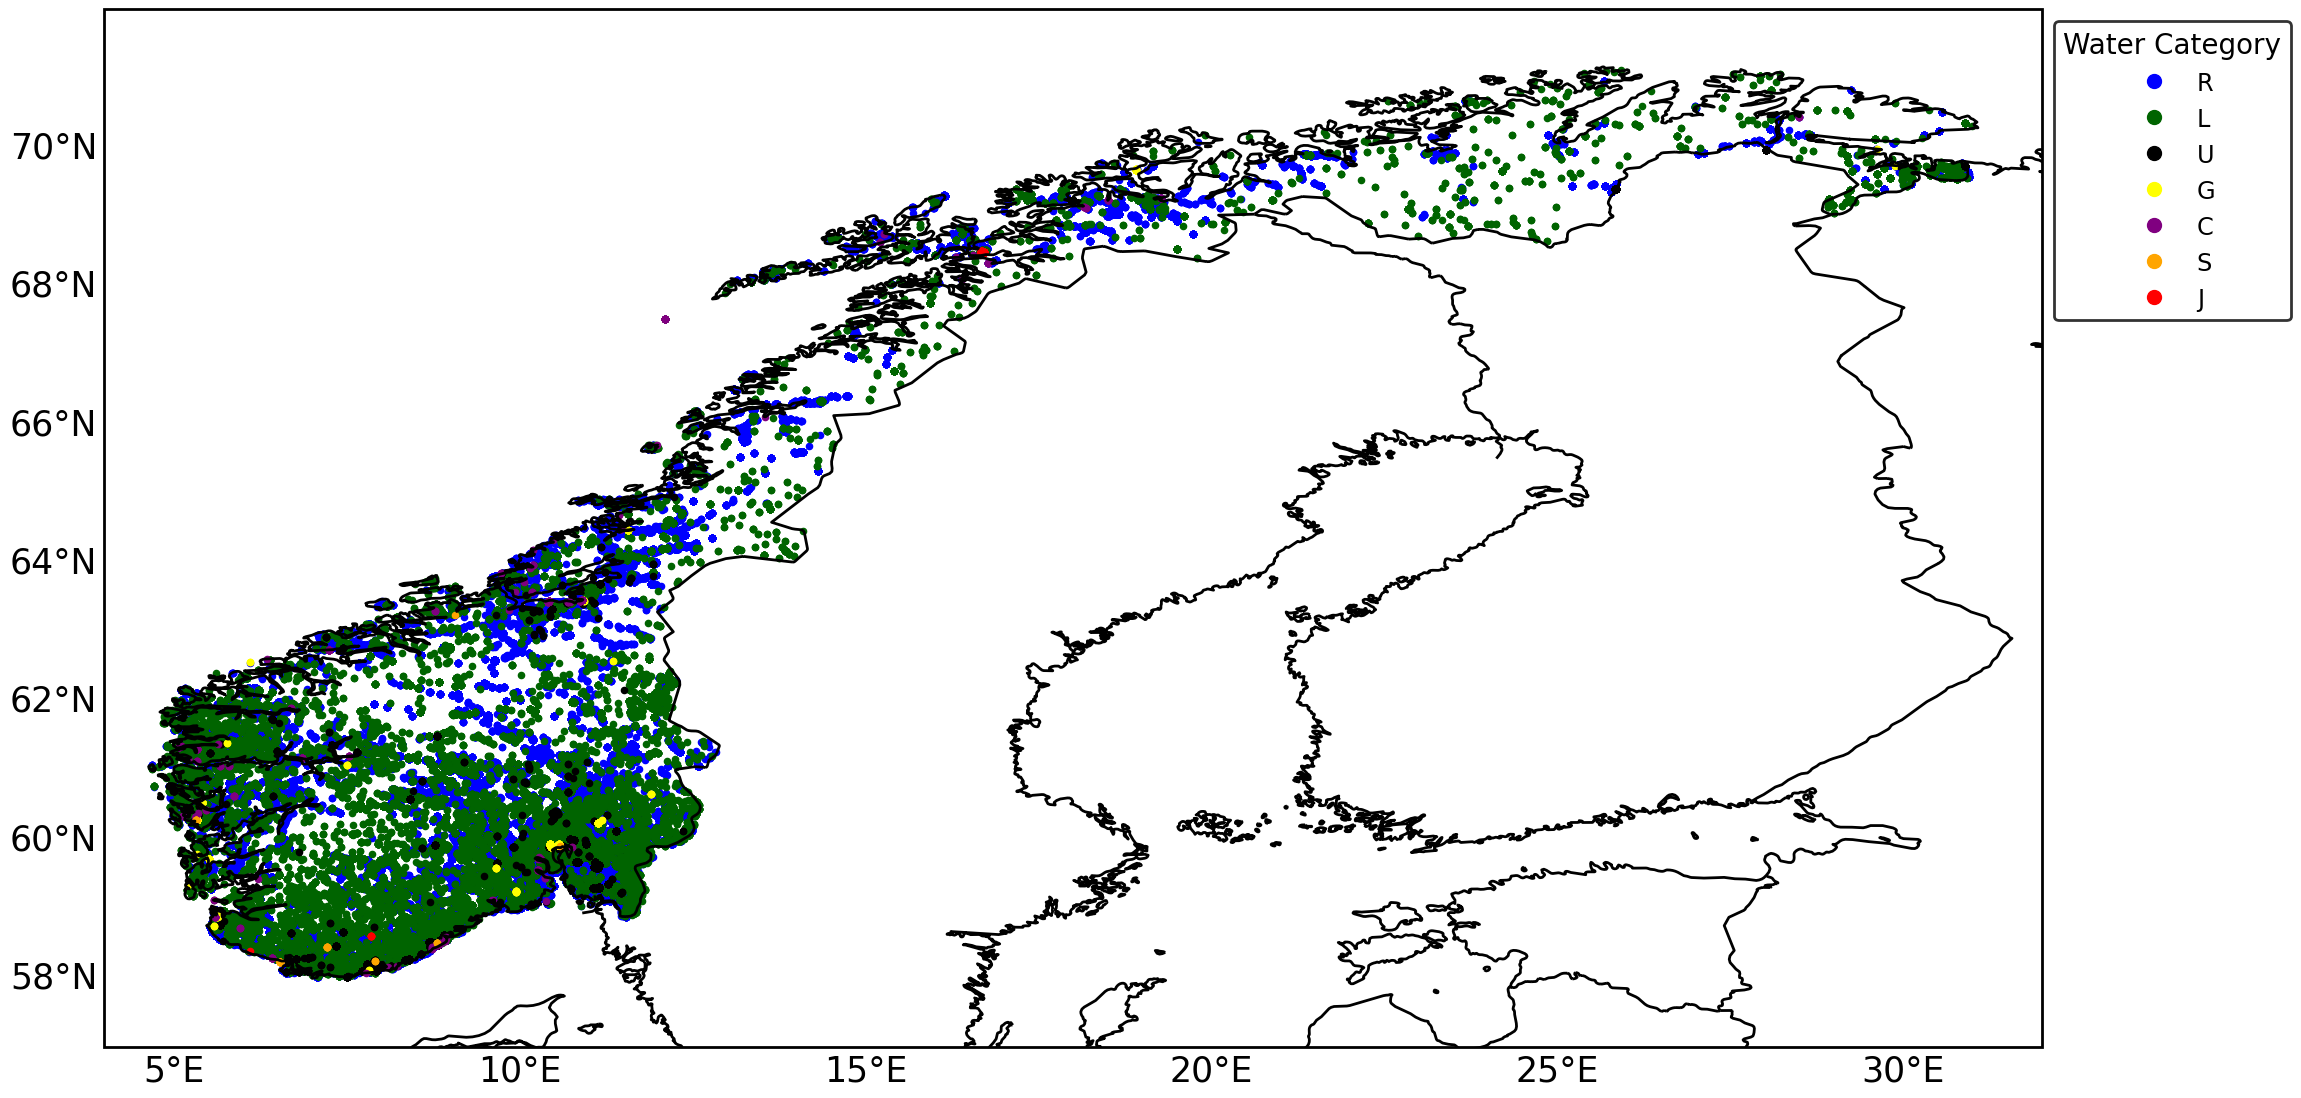

In [4]:
plot_map(merged_df['lon'], merged_df['lat'], merged_df['WaterCategory'])

#### Overview of the avaiable data for each water body

In [5]:
# Create a new column "lon_lat" that combines the longitude and latitude
merged_df["lon_lat"] = list(zip(merged_df.lon, merged_df.lat))

# Count the unique lon_lat pairs for each WaterCategory
unique_lon_lat_counts = merged_df.groupby("WaterCategory")["lon_lat"].nunique()

# Print the results
print(f"Number of unique lon-lat pairs for each \n{unique_lon_lat_counts}")

Number of unique lon-lat pairs for each 
WaterCategory
C       88
G       95
J       25
L     7432
R    12348
S       12
U      308
Name: lon_lat, dtype: int64


##### Select data in water category L and R

In [6]:
df_filtered = merged_df[merged_df['WaterCategory'].isin(['R', 'L'])]
df_filtered.head()

,WaterLocationID,WaterLocationCode,Name,ActivityID,ActivityName,MediumID,SamplingTime,UpperDepth,LowerDepth,N-TOT_µg_l,P-TOT_µg_l,DOC_mg_l,TOC_mg_l,lon,lat,WaterCategory,lon_lat
0,27839,001-27839,Bjørkelangen (BJØ1),ANNE,Annet,VF,1972-05-08,0.0,0.0,928.0,24.0,NaN,NaN,11.532832,59.848034,L,"(11.532832001025705, 59.8480339886724)"
1,27839,001-27839,Bjørkelangen (BJØ1),ANNE,Annet,VF,1972-05-08,1.0,1.0,868.0,38.0,NaN,NaN,11.532832,59.848034,L,"(11.532832001025705, 59.8480339886724)"
2,27839,001-27839,Bjørkelangen (BJØ1),ANNE,Annet,VF,1972-05-08,3.0,3.0,828.0,30.0,NaN,NaN,11.532832,59.848034,L,"(11.532832001025705, 59.8480339886724)"
3,27839,001-27839,Bjørkelangen (BJØ1),ANNE,Annet,VF,1972-05-08,5.0,5.0,828.0,33.0,NaN,NaN,11.532832,59.848034,L,"(11.532832001025705, 59.8480339886724)"
4,27839,001-27839,Bjørkelangen (BJØ1),ANNE,Annet,VF,1972-05-08,7.0,7.0,848.0,33.0,NaN,NaN,11.532832,59.848034,L,"(11.532832001025705, 59.8480339886724)"


##### Number of sites with complete data for TOC, DOC, TN, and TP

In [8]:
all_params_count = df_filtered[df_filtered[['N-TOT_µg_l', 'P-TOT_µg_l', 'DOC_mg_l', 'TOC_mg_l']].notna().all(axis=1)]['lon_lat'].nunique()

# Count the number of unique 'lon_lat' pairs that have data for both 'DOC_mg_l' and 'TOC_mg_l'
doc_toc_count = df_filtered[df_filtered[['DOC_mg_l', 'TOC_mg_l']].notna().all(axis=1)]['lon_lat'].nunique()

# Count the number of unique 'lon_lat' pairs that have data for both 'N-TOT_µg_l' and 'P-TOT_µg_l'
n_tot_p_tot_count = df_filtered[df_filtered[['N-TOT_µg_l', 'P-TOT_µg_l']].notna().all(axis=1)]['lon_lat'].nunique()

print(f"Number of sites with data for N-TOT, P-TOT, DOC, and TOC: {all_params_count}")
print(f"Number of sites with data for both DOC and TOC: {doc_toc_count}")
print(f"Number of sites with data for both N-TOT and P-TOT: {n_tot_p_tot_count}")

Number of sites with data for N-TOT, P-TOT, DOC, and TOC: 752
Number of sites with data for both DOC and TOC: 1294
Number of sites with data for both N-TOT and P-TOT: 14490


##### Number of sites with TOC, DOC, TN, and TP observations independently

In [9]:
# Filter the dataframe for rivers and lakes
df_filtered = df_filtered[df_filtered['WaterCategory'].isin(['R', 'L'])]

measurements = ['TOC_mg_l', 'DOC_mg_l', 'N-TOT_µg_l', 'P-TOT_µg_l']

results = {}
for measurement in measurements:
    counts = df_filtered[df_filtered[measurement].notnull()].groupby('WaterCategory')['lon_lat'].nunique()
    results[measurement] = counts

df_results = pd.DataFrame(results)
df_results

,TOC_mg_l,DOC_mg_l,N-TOT_µg_l,P-TOT_µg_l
WaterCategory,,,,
L,6204,1021,4734,5475
R,8895,476,10579,10605


#### Drop sites that only have DOC data

Parameter choice: 
* Rivers: there are about 9,000 river sites with TOC data, 10 000 with nutrient data. Not much DOC data
* Lakes: about 6000 sites with TOC data, 5 000 with nutrient data. A bit more DOC data (1000 sites)

Leah: we can probably drop DOC and just stick with TOC, TOTN and TOTP. Let's drop sites that only have DOC data from subsequent steps (data cleaning, catchment delineation, etc.).

In [10]:
# Number of sites that have only DOC measurements 
mask = df_filtered[['N-TOT_µg_l', 'P-TOT_µg_l', 'TOC_mg_l']].isna().all(axis=1) & df_filtered['DOC_mg_l'].notna()
num_sites = df_filtered.loc[mask, 'WaterLocationID'].nunique()
print(f"The number of sites that have only DOC data is {num_sites}.")

# Drop
df_filtered = df_filtered.dropna(subset=["N-TOT_µg_l", "P-TOT_µg_l", "TOC_mg_l"], how='all')
df_filtered.head()

The number of sites that have only DOC data is 195.


,WaterLocationID,WaterLocationCode,Name,ActivityID,ActivityName,MediumID,SamplingTime,UpperDepth,LowerDepth,N-TOT_µg_l,P-TOT_µg_l,DOC_mg_l,TOC_mg_l,lon,lat,WaterCategory,lon_lat
0,27839,001-27839,Bjørkelangen (BJØ1),ANNE,Annet,VF,1972-05-08,0.0,0.0,928.0,24.0,NaN,NaN,11.532832,59.848034,L,"(11.532832001025705, 59.8480339886724)"
1,27839,001-27839,Bjørkelangen (BJØ1),ANNE,Annet,VF,1972-05-08,1.0,1.0,868.0,38.0,NaN,NaN,11.532832,59.848034,L,"(11.532832001025705, 59.8480339886724)"
2,27839,001-27839,Bjørkelangen (BJØ1),ANNE,Annet,VF,1972-05-08,3.0,3.0,828.0,30.0,NaN,NaN,11.532832,59.848034,L,"(11.532832001025705, 59.8480339886724)"
3,27839,001-27839,Bjørkelangen (BJØ1),ANNE,Annet,VF,1972-05-08,5.0,5.0,828.0,33.0,NaN,NaN,11.532832,59.848034,L,"(11.532832001025705, 59.8480339886724)"
4,27839,001-27839,Bjørkelangen (BJØ1),ANNE,Annet,VF,1972-05-08,7.0,7.0,848.0,33.0,NaN,NaN,11.532832,59.848034,L,"(11.532832001025705, 59.8480339886724)"


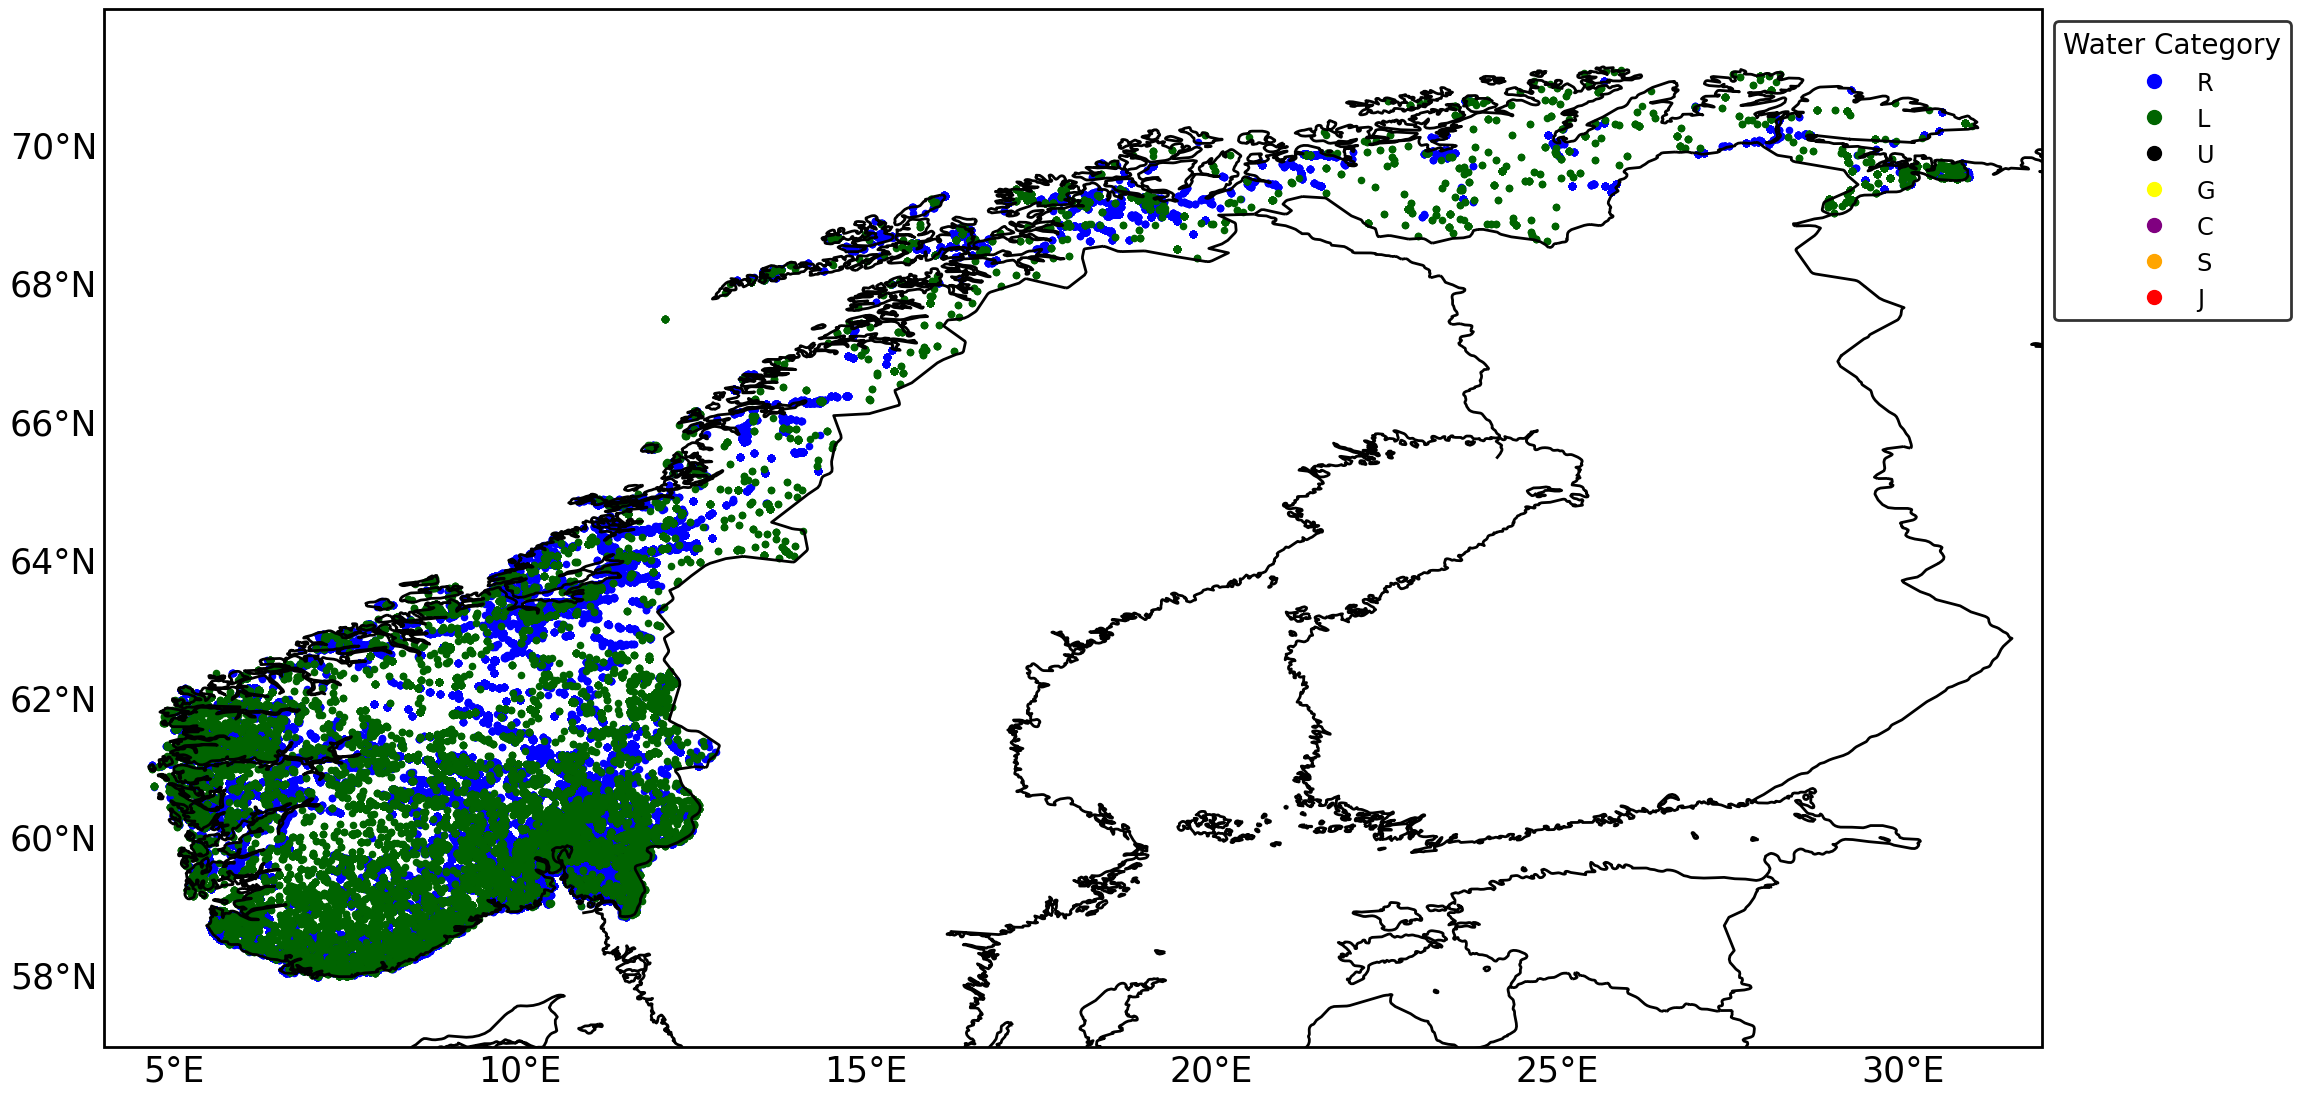

In [11]:
plot_map(df_filtered['lon'], df_filtered['lat'], df_filtered['WaterCategory'])

In [12]:
df_filtered.to_excel('../data/cleaned/water_chemistry/ai_wc_selected_sites.xlsx', index = False)